# TP interactif — Évaluer les modèles de Computer Vision

**Niveau : débutant / intermédiaire**  
**Trois tâches : classification d’images, détection d’objets, segmentation sémantique**

Objectifs : calculer et interpréter les métriques, visualiser les erreurs, comprendre les limites des scores.

> Ce notebook utilise de petites données artificielles pour rendre chaque calcul vérifiable. Il ne remplace pas une évaluation réelle sur un jeu de test indépendant ni le protocole COCO pour la détection.


## 1. Classification d’images

Imaginons un système qui reconnaît la présence (`1`) ou l’absence (`0`) d’un défaut sur une image.

- **TP** : défaut réellement présent et prédit comme présent.
- **FP** : fausse alarme.
- **FN** : défaut oublié.
- **TN** : absence de défaut correctement reconnue.

Formules :

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}$$
$$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN}$$
$$F_1=\frac{2\times \text{Precision}\times \text{Recall}}{\text{Precision}+\text{Recall}}$$


Matrice de confusion [lignes=réalité, colonnes=prédictions] :
[[55 10]
 [ 5 30]]
Accuracy : 85.00%
Précision classe défaut : 75.00%
Rappel classe défaut : 85.71%
F1 : 0.800
              precision    recall  f1-score   support

      Normal       0.92      0.85      0.88        65
      Défaut       0.75      0.86      0.80        35

    accuracy                           0.85       100
   macro avg       0.83      0.85      0.84       100
weighted avg       0.86      0.85      0.85       100



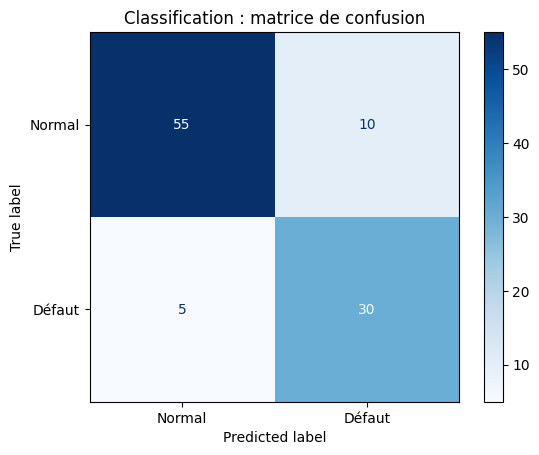

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, precision_score, recall_score, f1_score

# 30 TP, 5 FN, 10 FP, 55 TN
true_labels = np.array([1]*35 + [0]*65)
pred_labels = np.array([1]*30 + [0]*5 + [1]*10 + [0]*55)

cm = confusion_matrix(true_labels, pred_labels, labels=[0, 1])
print("Matrice de confusion [lignes=réalité, colonnes=prédictions] :")
print(cm)
print(f"Accuracy : {accuracy_score(true_labels, pred_labels):.2%}")
print(f"Précision classe défaut : {precision_score(true_labels, pred_labels):.2%}")
print(f"Rappel classe défaut : {recall_score(true_labels, pred_labels):.2%}")
print(f"F1 : {f1_score(true_labels, pred_labels):.3f}")
print(classification_report(true_labels, pred_labels, target_names=['Normal', 'Défaut']))
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Défaut']).plot(cmap='Blues', values_format='d')
plt.title('Classification : matrice de confusion')
plt.show()

### À retenir

Un modèle qui prédit toujours « normal » dans un jeu composé de 90 % d’images normales atteint **90 % d’accuracy**, mais un **rappel de 0 % pour les défauts**. Une métrique isolée peut donc tromper.

**Exercice :** pour la détection d’une maladie sur des images médicales, quel score souhaitez-vous surveiller en priorité si manquer un cas est particulièrement grave ?


## 2. Détection d’objets : IoU des rectangles

Un détecteur prédit une **catégorie**, une **confiance**, et un **rectangle** (bounding box).

$$IoU=\frac{\text{Aire de l'intersection}}{\text{Aire de l'union}}$$

Deux boîtes qui se recouvrent parfaitement ont un IoU de 1. Deux boîtes disjointes ont un IoU de 0.


IoU de la prédiction : 0.6807
À IoU >= 0.50 : TP
À IoU >= 0.75 : non correspondante


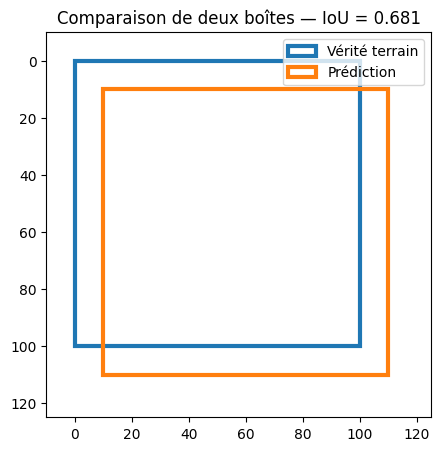

In [2]:
from matplotlib.patches import Rectangle

def box_iou(a, b):
    """a et b : rectangles [xmin, ymin, xmax, ymax]."""
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union else 0.0

ground_truth = [0, 0, 100, 100]
prediction = [10, 10, 110, 110]
iou = box_iou(ground_truth, prediction)
print(f'IoU de la prédiction : {iou:.4f}')
print('À IoU >= 0.50 :', 'TP' if iou >= 0.50 else 'non correspondante')
print('À IoU >= 0.75 :', 'TP' if iou >= 0.75 else 'non correspondante')

fig, ax = plt.subplots(figsize=(6, 5))
for box, label, color in [(ground_truth, 'Vérité terrain', 'tab:blue'), (prediction, 'Prédiction', 'tab:orange')]:
    ax.add_patch(Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], fill=False, linewidth=3, edgecolor=color, label=label))
ax.set(xlim=(-10, 125), ylim=(125, -10), title=f'Comparaison de deux boîtes — IoU = {iou:.3f}')
ax.set_aspect('equal'); ax.legend(); plt.show()

### Du matching à la mAP

Un objet prédit est généralement un **vrai positif** s’il a la bonne classe et correspond à une annotation encore non associée, avec un IoU supérieur au seuil retenu. Sinon, la prédiction est souvent un **faux positif** ; les vrais objets non détectés sont des **faux négatifs**. Les protocoles officiels gèrent aussi les exceptions (objets ignorés, foules, etc.).

La **courbe précision–rappel** est construite en faisant varier le seuil de confiance. L’**AP** résume cette courbe pour une classe ; la **mAP** moyenne les AP sur les classes. En COCO, on moyenne également les seuils d’IoU de 0.50 à 0.95 (pas de 0.05).

**Attention :** le calcul de l’IoU ci-dessus n’est pas un calcul de mAP. Pour un vrai benchmark, utiliser l’évaluateur COCO (`pycocotools`) ou l’évaluateur natif du framework, avec le protocole et les annotations adaptés.


## 3. Segmentation sémantique

On classe **chaque pixel**, par exemple `0 = arrière-plan`, `1 = voiture`. Il faut comparer le masque prédit au masque de référence.

$$\text{Pixel Accuracy}=\frac{\text{pixels correctement classés}}{\text{nombre total de pixels}}$$
$$IoU=\frac{|GT\cap Pred|}{|GT\cup Pred|},\quad Dice=\frac{2|GT\cap Pred|}{|GT|+|Pred|}$$

Un fond très grand peut gonfler la Pixel Accuracy même quand l’objet est mal segmenté.


Intersection = 16 pixels ; union = 34 pixels
IoU du masque = 0.4706
Dice = 0.6400
Pixel Accuracy = 0.7188


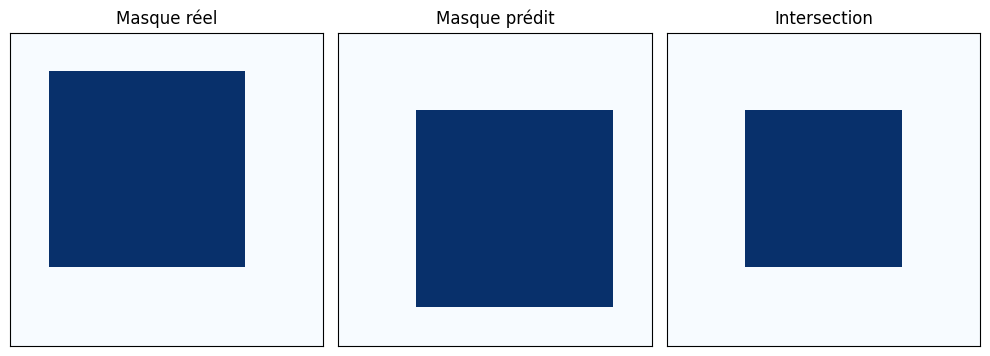

In [3]:
gt = np.zeros((8, 8), dtype=np.uint8)
pred = np.zeros((8, 8), dtype=np.uint8)
gt[1:6, 1:6] = 1
pred[2:7, 2:7] = 1

intersection = np.logical_and(gt, pred).sum()
union = np.logical_or(gt, pred).sum()
iou_mask = intersection / union if union else 1.0
dice = 2*intersection / (gt.sum()+pred.sum()) if gt.sum()+pred.sum() else 1.0
pixel_accuracy = (gt == pred).mean()
print(f'Intersection = {intersection} pixels ; union = {union} pixels')
print(f'IoU du masque = {iou_mask:.4f}')
print(f'Dice = {dice:.4f}')
print(f'Pixel Accuracy = {pixel_accuracy:.4f}')

fig, axs = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, mask, title in zip(axs, [gt, pred, np.logical_and(gt, pred)], ['Masque réel', 'Masque prédit', 'Intersection']):
    ax.imshow(mask, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### Segmentation multiclasses : mIoU

On calcule l’IoU séparément pour chaque catégorie (par exemple route, voiture, piéton) puis on en fait la moyenne : **mIoU**. Il faut annoncer si la classe « fond » a été incluse et comment sont traitées les classes absentes.


In [4]:
gt_multi = np.array([[0,0,1,1,1], [0,0,1,1,1], [0,2,2,1,1], [0,2,2,2,1], [0,0,2,2,1]])
pred_multi = np.array([[0,0,1,1,1], [0,1,1,1,1], [0,2,2,0,1], [0,2,0,2,1], [0,0,2,1,1]])
ious = {}
for cls in [0,1,2]:
    real = gt_multi == cls
    estimated = pred_multi == cls
    u = np.logical_or(real, estimated).sum()
    i = np.logical_and(real, estimated).sum()
    ious[cls] = float(i/u) if u else np.nan
print('IoU par classe :', {k: round(v, 3) for k,v in ious.items()})
print('mIoU (classes 0,1,2) :', round(float(np.nanmean(list(ious.values()))), 3))

IoU par classe : {0: 0.7, 1: 0.75, 2: 0.714}
mIoU (classes 0,1,2) : 0.721


## 4. Pourquoi Dice est souvent plus élevé que IoU ?

Pour un même couple de masques binaires, avec dénominateurs non nuls :

$$Dice=\frac{2IoU}{1+IoU}$$

Ces deux métriques sont liées ; elles ne fournissent pas deux informations totalement indépendantes. Elles ne sont cependant pas identiques numériquement.


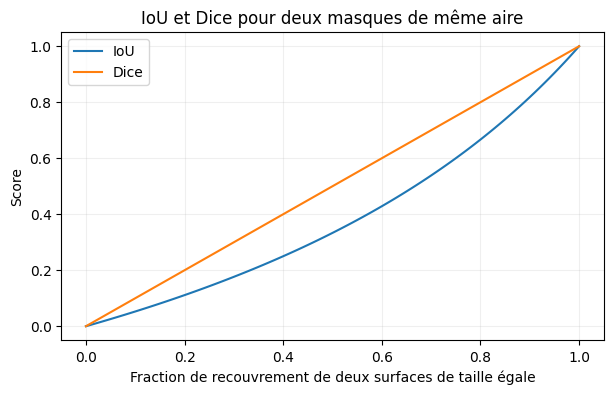

In [5]:
overlaps = np.linspace(0, 1, 101)
ious_curve = overlaps / (2 - overlaps)
dice_curve = overlaps
plt.figure(figsize=(7, 4))
plt.plot(overlaps, ious_curve, label='IoU')
plt.plot(overlaps, dice_curve, label='Dice')
plt.xlabel('Fraction de recouvrement de deux surfaces de taille égale')
plt.ylabel('Score')
plt.title('IoU et Dice pour deux masques de même aire')
plt.grid(alpha=0.2); plt.legend(); plt.show()

## 5. Segmentation d’instances

La segmentation sémantique met tous les pixels « voiture » dans la même classe ; la segmentation d’instances distingue **voiture 1**, **voiture 2**, etc.

L’évaluation d’instances combine donc **correspondance objet par objet**, **IoU des masques**, **confiance**, **AP / mAP**. Le protocole COCO est similaire à la détection, mais calcule l’IoU sur les **masques** plutôt que sur les **bounding boxes**.

## 6. Guide de sélection rapide

| Tâche | À rapporter en priorité | Analyse complémentaire |
|:--|:--|:--|
| Classification | Macro-F1, précision/rappel par classe | Matrice de confusion, accuracy |
| Détection | mAP@0.50:0.95, AP par classe | AP@0.50, petits objets, précision/rappel |
| Segmentation sémantique | mIoU par classe | Dice, Pixel Accuracy, inspection des masques |
| Segmentation d’instances | Mask mAP@0.50:0.95 | Mask AP par classe et taille |

## 7. Questions de révision

1. Pourquoi 95 % d'accuracy peut-il être un mauvais résultat ?
2. Quelle est la différence entre « IoU des boîtes » et « IoU des masques » ?
3. Une prédiction avec IoU 0.68 compte-t-elle comme un TP à un seuil d'IoU de 0.75 ?
4. Pourquoi mAP@0.50 est-elle souvent supérieure à mAP@0.50:0.95 ?
5. Pourquoi faut-il présenter des résultats par classe, et pas seulement une moyenne ?

### Références

- COCO Evaluation : https://cocodataset.org/dataset/detection-eval.htm
- Scikit-learn classification : https://scikit-learn.org/stable/modules/model_evaluation.html
- Scikit-learn IoU/Jaccard : https://scikit-learn.org/stable/modules/generated/sklearn.metrics.jaccard_score.html
